# Name That LLM: understand the data before training

A CPU-only guide to inspecting class balance, comparing responses to the same prompt, and constructing a prompt-disjoint validation split.

**What this notebook does:** audits the host training set, plots simple style measurements, and checks a reproducible split. **What it does not claim:** a competitive classifier, a leaderboard score, or proof that a visible stylistic difference generalizes.

Attach the [official competition data](https://www.kaggle.com/competitions/name-that-llm/data) before running. Data credit belongs to the competition organizers; this notebook does not redistribute a copy of the CSV. Analysis code was prepared with AI assistance and checked on the training file.


In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sklearn.model_selection import GroupShuffleSplit

candidates = list(Path('/kaggle/input').rglob('train.csv')) if Path('/kaggle/input').exists() else []
local = Path('data/name-that-llm/train.csv')
if local.exists(): candidates.append(local)
valid = []
for path in candidates:
    header = pd.read_csv(path, nrows=0).columns
    if {'id', 'prompt_id', 'text', 'model'}.issubset(header): valid.append(path)
if len(valid) != 1:
    raise ValueError(f'Expected one matching training file; found {len(valid)}. Attach only the official competition dataset.')
path = valid[0]
df = pd.read_csv(path, dtype={'id': str, 'prompt_id': str, 'text': str, 'model': str})
assert df[['id','prompt_id','text','model']].notna().all().all()
assert df.id.is_unique
print('Training file SHA-256:', hashlib.sha256(path.read_bytes()).hexdigest())
display(pd.Series({'passages':len(df),'prompts':df.prompt_id.nunique(),'models':df.model.nunique(),
                   'duplicate_text_rows':int(df.text.duplicated().sum())}).to_frame('count'))

Training file SHA-256: 40a22ce8d88c5f46feb4637a099db815bef5f713ffe53e89dbe1b7b21de77707


,count
passages,2699
prompts,150
models,18
duplicate_text_rows,0


## 1. Is each prompt represented by every model?

The table below checks coverage rather than assuming a perfectly rectangular dataset. A missing response matters when writing validation checks; it is not a reason to invent or duplicate a training example.


In [2]:
coverage = pd.crosstab(df.prompt_id, df.model)
display(df.model.value_counts().sort_index().rename('passages').to_frame())
print('Missing prompt/model cells:', int((coverage == 0).sum().sum()))
print('Repeated prompt/model cells:', int((coverage > 1).sum().sum()))
display(coverage.sum(axis=1).value_counts().sort_index().rename_axis('passages per prompt').to_frame('prompt count'))

,passages
model,
claude-fable-5,149
claude-opus-4-6,150
claude-opus-4-8,150
claude-opus-5,150
claude-sonnet-5,150
gemini-3.1-pro-preview,150
gemini-3.6-flash,150
gemini-3.7-flash,150
gemini-3.8-flash,150


Missing prompt/model cells: 1
Repeated prompt/model cells: 0


,prompt count
passages per prompt,
17,1
18,149


## 2. Which surface features differ?

Character count, whitespace-separated word count, punctuation and paragraph breaks are inexpensive measurements. They can reflect a model's formatting habits, but also prompt content and generation settings. These are **descriptive comparisons on training data**, not evidence of predictive accuracy. Character/word counts also depend on language.


,characters,words,newlines_per_1000_chars,question_marks_per_1000_chars
model,,,,
claude-fable-5,646.0,100.0,0.0,0.0
claude-opus-4-6,687.5,98.5,0.0,0.0
claude-opus-4-8,731.5,109.0,0.0,0.0
claude-opus-5,725.5,116.5,0.0,0.0
claude-sonnet-5,707.0,99.5,0.0,0.0
gemini-3.1-pro-preview,714.0,104.0,0.0,0.0
gemini-3.6-flash,634.5,95.5,0.0,0.0
gemini-3.7-flash,717.5,101.5,0.0,0.0
gemini-3.8-flash,583.0,84.0,0.0,0.0


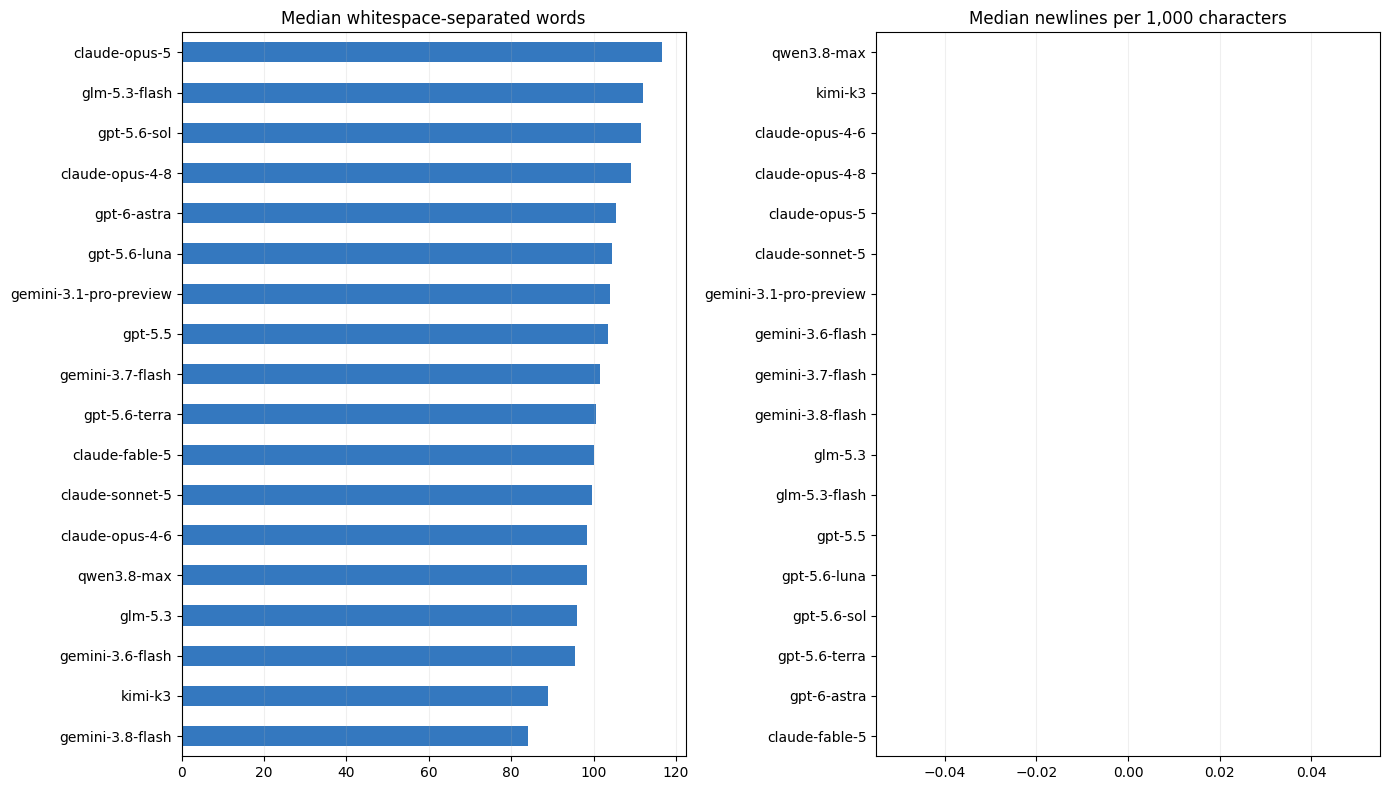

In [3]:
features = pd.DataFrame(index=df.index)
features['characters'] = df.text.str.len()
features['words'] = df.text.str.split().str.len()
features['newlines_per_1000_chars'] = 1000 * df.text.str.count('\n') / features.characters.clip(lower=1)
features['question_marks_per_1000_chars'] = 1000 * df.text.str.count(r'\?') / features.characters.clip(lower=1)
features['model'] = df.model
summary = features.groupby('model').median(numeric_only=True)
display(summary.round(2))
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
summary.words.sort_values().plot.barh(ax=axes[0], color='#3478bf', title='Median whitespace-separated words')
summary.newlines_per_1000_chars.sort_values().plot.barh(ax=axes[1], color='#648c54', title='Median newlines per 1,000 characters')
for ax in axes: ax.set_ylabel(''); ax.grid(axis='x', alpha=.2)
plt.tight_layout(); plt.show()

## 3. Compare like with like

Choose one prompt ID and two source models. Reading responses to the **same prompt** helps separate topic differences from writing differences. The viewer is interactive when widgets are supported; the fallback is a callable function. Text is HTML-escaped so a passage cannot inject markup into the display.

No raw passages are saved into the published notebook outputs. Run the viewer yourself after attaching the competition data.


In [4]:
import html

def compare(prompt_id, model_a, model_b):
    subset = df[df.prompt_id == str(prompt_id)]
    sections = []
    for model in [model_a, model_b]:
        matches = subset[subset.model == model].text
        text = matches.iloc[0] if len(matches) else '(No response for this prompt/model.)'
        sections.append('<section style="flex:1;min-width:250px;padding:12px;border:1px solid #aaa">'
                        + '<h3>' + html.escape(model) + '</h3><div style="white-space:pre-wrap">'
                        + html.escape(text) + '</div></section>')
    display(HTML('<div style="display:flex;gap:12px;flex-wrap:wrap">'+''.join(sections)+'</div>'))

def launch_viewer():
    import ipywidgets as widgets
    models = sorted(df.model.unique())
    # Explicit button prevents automatic passage rendering on notebook execution.
    return widgets.interact_manual(compare,
        prompt_id=widgets.Dropdown(options=sorted(df.prompt_id.unique())),
        model_a=widgets.Dropdown(options=models, value=models[0]),
        model_b=widgets.Dropdown(options=models, value=models[1]))

print('Run launch_viewer() in a new cell, or call compare(prompt_id, model_a, model_b).')

Run launch_viewer() in a new cell, or call compare(prompt_id, model_a, model_b).


## 4. Hold out prompts, not individual rows

If responses to the same prompt appear on both sides of a random row split, topic overlap can make validation less representative of unseen prompts. Here we keep every prompt wholly on one side.

This is a **single illustrative holdout**, not the experiment split used to select any existing submission. Use multiple prompt-disjoint folds for serious model comparisons. Exact prompt separation does not guarantee separation of closely related topics; review that separately. Fit vocabulary, scaling and any learned transformation using the training subset only.

Reference: [scikit-learn GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html).


In [5]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=2026)
train_idx, valid_idx = next(splitter.split(df, y=df.model, groups=df.prompt_id))
train, valid = df.iloc[train_idx], df.iloc[valid_idx]
assert set(train.prompt_id).isdisjoint(valid.prompt_id)
assert set(train.index).isdisjoint(valid.index)
print('Shared prompt IDs:', len(set(train.prompt_id) & set(valid.prompt_id)))
print('Exact text overlap:', len(set(train.text) & set(valid.text)))
display(pd.DataFrame({'training':train.model.value_counts(), 'validation':valid.model.value_counts()}).fillna(0).astype(int).sort_index())
print('Training:', len(train), 'rows;', train.prompt_id.nunique(), 'prompts')
print('Validation:', len(valid), 'rows;', valid.prompt_id.nunique(), 'prompts')

Shared prompt IDs: 0
Exact text overlap: 0


,training,validation
model,,
claude-fable-5,119,30
claude-opus-4-6,120,30
claude-opus-4-8,120,30
claude-opus-5,120,30
claude-sonnet-5,120,30
gemini-3.1-pro-preview,120,30
gemini-3.6-flash,120,30
gemini-3.7-flash,120,30
gemini-3.8-flash,120,30


Training: 2159 rows; 120 prompts
Validation: 540 rows; 30 prompts


## Next steps

1. Freeze your prompt splits before comparing models.
2. Start with an inexpensive text classifier and record held-out predictions.
3. Inspect per-model errors, not only one aggregate score.
4. Compare changes on the same held-out examples and report uncertainty across prompts.
5. Check the competition rules and metric before adding external data or submitting.

This notebook deliberately stops at exploration and validation design. Its charts do not establish reliable fingerprints, and it makes no claim about hidden-test performance.
